In [ ]:
import re
import sys
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt 
import nltk
import numpy as np 
import pandas as pd 
import spacy
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

In [ ]:
ROOT=Path.cwd().parent
sys.path.append(str(ROOT))
# from src.clean_pipeline import (
#     FEATURES_RE,
#     HEADER_RE,
#     DIALOGUE_RE,
#     clean_text,
#     extract_label
# )
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

In [ ]:
df = pd.read_csv(ROOT / "data" / "raw_tinystories.csv")
print(df.shape)
df["n_words"] = df["story"].str.split().str.len()
print(df["n_words"].describe().round(1))
print(df.groupby("narrative_type")["n_words"].mean().round(1))
print(df["narrative_type"].value_counts())

(15000, 8)
count    15000.0
mean       171.9
std         70.7
min         61.0
25%        136.0
50%        154.0
75%        179.0
max        846.0
Name: n_words, dtype: float64
narrative_type
Conflict      168.2
Dialogue      179.9
MoralValue    167.5
Name: n_words, dtype: float64
narrative_type
Conflict      5000
Dialogue      5000
MoralValue    5000
Name: count, dtype: int64


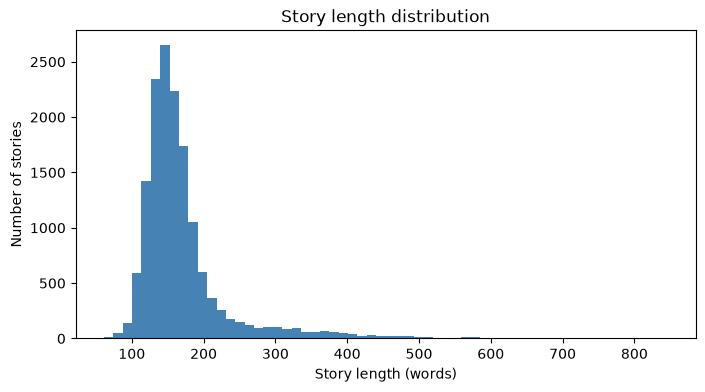

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["n_words"], bins=60, color="steelblue")
ax.set_xlabel("Story length (words)")
ax.set_ylabel("Number of stories")
ax.set_title("Story length distribution")
fig.savefig(FIG_DIR / "length_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
all_tokens = []
for story in df["story"]:
    text = story.lower().replace("’", "'")
    all_tokens.extend(WORD_RE.findall(text))
counts = Counter(all_tokens)
n_tokens = len(all_tokens)
n_types = len(counts)
hapax = sum(1 for c in counts.values() if c == 1)
print(f"Tokens: {n_tokens:,}")
print(f"Types (vocabulary): {n_types:,}")
print(f"Type/token ratio: {n_types / n_tokens:.4f}")
print(f"Hapax legomena: {hapax:,} ({hapax / n_types:.1%} of types)")
print(counts.most_common(20))

Tokens: 2,578,251
Types (vocabulary): 9,725
Type/token ratio: 0.0038
Hapax legomena: 2,126 (21.9% of types)
[('the', 136328), ('and', 119760), ('to', 99420), ('a', 80207), ('was', 63373), ('he', 51903), ('she', 48518), ('they', 42860), ('it', 39910), ('her', 36260), ('that', 27193), ('lily', 24776), ('his', 24501), ('with', 22984), ('but', 22516), ('day', 21978), ('in', 21061), ('said', 20874), ('you', 19135), ('of', 17423)]


Zipf slope over top   100 ranks: -0.84
Zipf slope over top  1000 ranks: -1.20
Zipf slope over top  9725 ranks: -2.07
Top 10 words cover 27.9% of all tokens


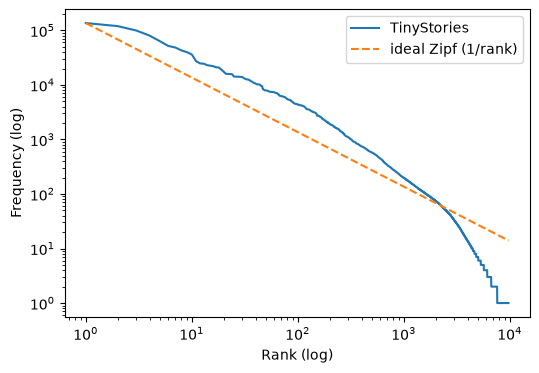

In [ ]:
freqs = np.array(sorted(counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
for n in [100, 1000, len(freqs)]:
    slope = np.polyfit(np.log10(ranks[:n]), np.log10(freqs[:n]), 1)[0]
    print(f"Zipf slope over top {n:>5} ranks: {slope:.2f}")
print(f"Top 10 words cover {freqs[:10].sum() / n_tokens:.1%} of all tokens")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ranks, freqs, label="TinyStories")
ax.loglog(ranks, freqs[0] / ranks, "--", label="ideal Zipf (1/rank)")
ax.set_xlabel("Rank (log)")
ax.set_ylabel("Frequency (log)")
ax.legend()
fig.savefig(FIG_DIR / "zipf.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
print(df.loc[0, "raw_text"])

Summary: A whale is happy swimming in the ocean until it gets caught in a net by people on a boat. Other whales come to its rescue and help it escape.
Words: tear, whale, rough
Features: Conflict
Story: Once upon a time, there was a big whale swimming in the ocean. The whale was very happy because the water was calm and smooth. Suddenly, a big wave came and the water became very rough. The whale was scared and didn't know what to do.
Then, the whale saw a small boat with people inside. The people were trying to catch the whale with a big net. The whale knew this was bad and tried to swim away, but the net tore a big hole in the whale's skin. The whale was in pain and didn't know how to escape.
Luckily, some other whales saw what was happening and came to help. They pushed the boat away and helped the injured whale. The whale was grateful and happy to have friends to help. From that day on, the whale knew to be careful of rough waters and mean people in boats.
<|endoftext|>


In [ ]:
MESSY_PATTERNS = {
    "curly quotes": r"[“”’]",
    "long dash": r"[—–]",
    "ellipsis": r"…|\.{3,}",
    "double space": r"  ",
    "summary after story": r"\nSummary:[^\n]*\n<\|endoftext",
}
for name, pattern in MESSY_PATTERNS.items():
    hits = df["raw_text"].str.contains(pattern, regex=True)
    first = df.index[hits][0]
    m = re.search(pattern, df.loc[first, "raw_text"])
    snippet = df.loc[first, "raw_text"][max(0, m.start() - 60): m.end() + 60]
    print(f"--- {name}: {hits.sum()} stories (example id {first})")
    print(repr(snippet))


--- curly quotes: 474 stories (example id 103)
'ggle. "Mommy, look at the fire!" she exclaimed. \nMommy said “Yes, darling, that’s a fire. Let’s go over and have a look.”'
--- long dash: 62 stories (example id 229)
'\nFrom that day on, the bird remembered its mum’s wise words – "Be patient, everything will work out in the end". The bird'
--- ellipsis: 26 stories (example id 257)
'ee the butterfly and the dog and the bird and the flower and..."\nHer mom laughed and said, "Yes, Lily, maybe we can. But re'
--- double space: 329 stories (example id 18)
'ins a card with nice words that make them both happy.\nStory:  \nGrandma was walking with her granddaughter. As they walked,'
--- summary after story: 4531 stories (example id 6)
'urtle just smiled and said, "Slow and steady wins the race."\nSummary: A fast rabbit and a slow turtle have a race, with the rabbit taking a nap mid-race and the turtle eventually winning by being steady and persistent.\n<|endoftext|>'


In [ ]:
stops = nlp.Defaults.stop_words
print(f"spaCy has {len(stops)} stop words")
for w in ["i", "you", "we", "not", "no"]:
    print(f"{w!r} in stop list: {w in stops}")
for w in ["i", "you", "we", "not"]:
    rate = df.groupby("narrative_type")["story_clean"].apply(
        lambda s: s.str.lower().str.count(rf"\b{w}\b").mean())
    print(w, rate.round(2).to_dict())


: 

In [ ]:
stemmer = PorterStemmer()
words = ["cried", "jumped", "puppies", "happily", "running", "was", "flies", "studies"]
print("Stem :", [stemmer.stem(w) for w in words])
print("Lemma:", [nlp(w)[0].lemma_ for w in words])
doc = nlp("Lily cried because the puppies were running and the flies were buzzing.")
print([(t.text, t.lemma_) for t in doc if t.is_alpha])


In [ ]:
clean = pd.read_csv(ROOT / "data" / "cleaned_tinystories.csv")
vocab_raw = Counter(tok for text in df["raw_text"] for tok in text.split())
vocab_mid = Counter(tok for text in df["story_clean"] for tok in WORD_RE.findall(text.lower()))
vocab_final = Counter(tok for text in clean["text_processed"].fillna("") for tok in text.split())
summary = pd.DataFrame({
    "stage": ["raw (whitespace split)", "after noise removal + lowercase", "after lemmatization"],
    "vocabulary size": [len(vocab_raw), len(vocab_mid), len(vocab_final)],
})
print(summary.to_string(index=False))
clean.head()
